Based on [this](https://github.com/bashartalafha/Arabizi-Transliteration).

*Training was done locally*

In [2]:
from __future__ import print_function
from timeit import default_timer

import pandas as pd
import numpy as np

from keras.layers import Input, Embedding, LSTM, Bidirectional, TimeDistributed, Dense, Activation, dot, concatenate
from keras.models import Model
from keras.utils import Sequence

In [3]:
CHAR_CODE_START = 1
CHAR_CODE_PADDING = 0

LEARNING_RATE = 0.3
BATCH_SIZE = 128
HIDDEN_NODES = 128
EMB_SIZE=64

INPUT_LENGTH = 64
OUTPUT_LENGTH = 64

## Transform and translate data

In [4]:
# All symbols
token_transform = {
    'tg':'абвгғдеёжзиӣйкқлмнопрстуӯфхҳчҷшъэюяь' + '-~ ',
    'fa':'ابپتثجچحخدذرزژسشصضطظعغفقکگلمنوهی' + 'هٔئّْآ' + '-ي\u200c ',
    }


def build_characters_encoding(names):
    """
    :param names: list of strings
    :return: (encoding, decoding, count)
    """
    count = 2
    encoding = {}
    decoding = {1: 'START'}
    for c in set([c for name in names for c in name]):
        encoding[c] = count
        decoding[count] = c
        count += 1
    return encoding, decoding, count


def transform(encoding, data, vector_size=64):
    """
    :param encoding: encoding dict built by build_characters_encoding()
    :param data: list of strings
    :param vector_size: size of each encoded vector
    """
    transformed_data = np.zeros(shape=(len(data), vector_size))
    for n, line in enumerate(data):
        for char in range(min(len(line), vector_size+1)):
            transformed_data[n][char] = encoding[line[char]]
    return transformed_data

In [5]:
# DataGenerator will encode data as needed

input_encoding = {i:n for n, i in enumerate(token_transform['tg'], start=2)}
output_encoding = {i:n for n, i in enumerate(token_transform['fa'], start=2)}
output_decoding = {**{1:'START'}, **{n:i for n, i in enumerate(token_transform['fa'], start=2)}}
input_dict_size = max(input_encoding.values()) + 1
output_dict_size = max(output_decoding) + 1

class DataGenerator(Sequence):
    def __init__(self, df, indexes,
                 input_encoding, output_encoding,
                 batch_size=64, shuffle=True,
                 input_length=INPUT_LENGTH,
                 output_length=OUTPUT_LENGTH,
                 char_code_start=CHAR_CODE_START):
        self.df = df
        self.batch_size = batch_size
        self.indexes = list(indexes)

        self.input_encoding = input_encoding
        self.output_encoding = output_encoding
        self.input_length = input_length
        self.output_length = output_length
        self.output_dict_size = max(output_encoding.values()) + 1
        self.char_code_start=char_code_start

        self.shuffle = shuffle
        self.on_epoch_end()
    
    def __len__(self):
        'Denotes the number of batches per epoch'
        return int(np.floor(len(self.indexes) / self.batch_size))

    def __getitem__(self, index):
        'Generate one batch of data'
        # Generate indexes of the batch
        temp_indexes = self.indexes[index*self.batch_size:(index+1)*self.batch_size]

        # Generate data
        X, y = self.__data_generation(temp_indexes)

        return X, y

    def on_epoch_end(self):
        'Updates indexes after each epoch'
        if self.shuffle == True:
            np.random.shuffle(self.indexes)

    def __data_generation(self, temp_indexes):
        'Generates data containing batch_size samples'
        data = self.df.loc[temp_indexes]
        X = data['tg']
        y = data['fa']

        encoded_X = transform(
            self.input_encoding, X, vector_size=self.input_length)
        encoded_y = transform(
            self.output_encoding, y, vector_size=OUTPUT_LENGTH)
        
        decoder_input = np.zeros_like(encoded_y)
        decoder_input[:, 1:] = encoded_y[:,:-1]
        decoder_input[:, 0] = CHAR_CODE_START
        decoder_output = np.eye(self.output_dict_size)[encoded_y.astype('int')]

        return [encoded_X, decoder_input], [decoder_output]

In [6]:
def generate(model, text):
    encoder_input = transform(input_encoding, [text.lower()], INPUT_LENGTH)
    decoder_input = np.zeros(shape=(len(encoder_input), OUTPUT_LENGTH))
    decoder_input[:,0] = CHAR_CODE_START
    for i in range(1, OUTPUT_LENGTH):
        output = model.predict([encoder_input, decoder_input], verbose=0).argmax(axis=2)
        decoder_input[:,i] = output[:,i]
    return decoder_input [:,1:]

def decode(sequence):
    sequence = sequence.tolist()
    sequence = sequence[:sequence.index(0)]
    return ''.join(output_decoding[i] for i in sequence)

def translate(model, text):
    decoder_output = generate(model, text)
    return decode(decoder_output[0])

In [15]:
train = pd.read_csv('./data/train.csv').dropna().drop_duplicates()
val = pd.read_csv('./data/val.csv').dropna().drop_duplicates()
test = pd.read_csv('./data/test.csv').dropna().drop_duplicates()

print('Train length =', len(train))
print('Val length =', len(val))
print('Test length =', len(test))

Train length = 4252825
Val length = 254240
Test length = 2256


In [16]:
training_generator = DataGenerator(train, train.index, input_encoding, output_encoding, batch_size=BATCH_SIZE)
validation_generator = DataGenerator(val, val.index, input_encoding, output_encoding, batch_size=BATCH_SIZE)

## Model

In [18]:
encoder_input = Input(shape=(INPUT_LENGTH,))
decoder_input = Input(shape=(OUTPUT_LENGTH,))

### Encoder / Decoder


In [19]:
encoder = Embedding(input_dict_size, EMB_SIZE, input_length=INPUT_LENGTH, mask_zero=True)(encoder_input)
encoder = Bidirectional(LSTM(int(HIDDEN_NODES/2), return_sequences=True, dropout=0.1))(encoder)
encoder_last = encoder[:,-1,:]

print('encoder', encoder)
print('encoder_last', encoder_last)

decoder = Embedding(output_dict_size, EMB_SIZE, input_length=OUTPUT_LENGTH, mask_zero=True)(decoder_input)
decoder = LSTM(HIDDEN_NODES, return_sequences=True, dropout=0.1)(decoder, initial_state=[encoder_last, encoder_last])

print('decoder', decoder)

encoder KerasTensor(type_spec=TensorSpec(shape=(None, 64, 128), dtype=tf.float32, name=None), name='bidirectional/concat:0', description="created by layer 'bidirectional'")
encoder_last KerasTensor(type_spec=TensorSpec(shape=(None, 128), dtype=tf.float32, name=None), name='tf.__operators__.getitem/strided_slice:0', description="created by layer 'tf.__operators__.getitem'")
decoder KerasTensor(type_spec=TensorSpec(shape=(None, 64, 128), dtype=tf.float32, name=None), name='lstm_1/PartitionedCall:1', description="created by layer 'lstm_1'")


### Attention Mechanism

In [20]:
attention = dot([decoder, encoder], axes=[2, 2])
attention = Activation('softmax', name='attention')(attention)
print('attention', attention)

context = dot([attention, encoder], axes=[2,1])
print('context', context)

decoder_combined_context = concatenate([context, decoder])
print('decoder_combined_context', decoder_combined_context)

output = TimeDistributed(Dense(HIDDEN_NODES, activation="tanh"))(decoder_combined_context)
output = TimeDistributed(Dense(output_dict_size, activation="softmax"))(output)
print('output', output)

attention KerasTensor(type_spec=TensorSpec(shape=(None, 64, 64), dtype=tf.float32, name=None), name='attention/Softmax:0', description="created by layer 'attention'")
context KerasTensor(type_spec=TensorSpec(shape=(None, 64, 128), dtype=tf.float32, name=None), name='dot_1/MatMul:0', description="created by layer 'dot_1'")
decoder_combined_context KerasTensor(type_spec=TensorSpec(shape=(None, 64, 256), dtype=tf.float32, name=None), name='concatenate/concat:0', description="created by layer 'concatenate'")
output KerasTensor(type_spec=TensorSpec(shape=(None, 64, 44), dtype=tf.float32, name=None), name='time_distributed_1/Reshape_1:0', description="created by layer 'time_distributed_1'")


In [24]:
model = Model(inputs=[encoder_input, decoder_input], outputs=[output])
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics='categorical_accuracy')

In [22]:
model.summary()

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_5 (InputLayer)        [(None, 64)]                 0         []                            
                                                                                                  
 embedding_12 (Embedding)    (None, 64, 64)               2624      ['input_5[0][0]']             
                                                                                                  
 input_6 (InputLayer)        [(None, 64)]                 0         []                            
                                                                                                  
 bidirectional_10 (Bidirect  (None, 64, 128)              66048     ['embedding_12[0][0]']        
 ional)                                                                                     

### Training

In [ ]:
import pickle

epoch = 0
for _ in range(4):
    epoch += 1
    print(f'Training {epoch} epoch...')
    history = model.fit(x=training_generator, validation_data=validation_generator,
                        verbose=2, epochs=1)
    model.save(f'model_{epoch}.h5')
    with open(f'history_{epoch}', 'wb') as f:
        pickle.dump(history, f)

## Evaluation

In [23]:
acc = []
val_acc = []
loss = []
val_loss = []

for i in range(1, 5):
    with open(f'./history_{i}', 'rb') as f:
        history = pickle.load(f)
        acc.append(history.history['categorical_accuracy'])
        val_acc.append(history.history['val_categorical_accuracy'])
        loss.append(history.history['loss'])
        val_loss.append(history.history['val_loss'])

In [4]:
%matplotlib inline  
import matplotlib.pyplot as plt
import seaborn as sns

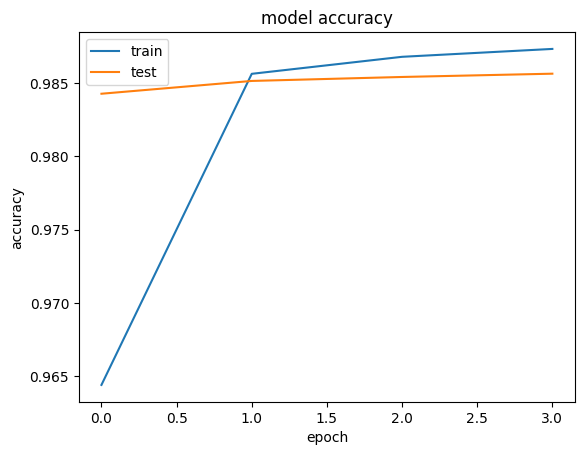

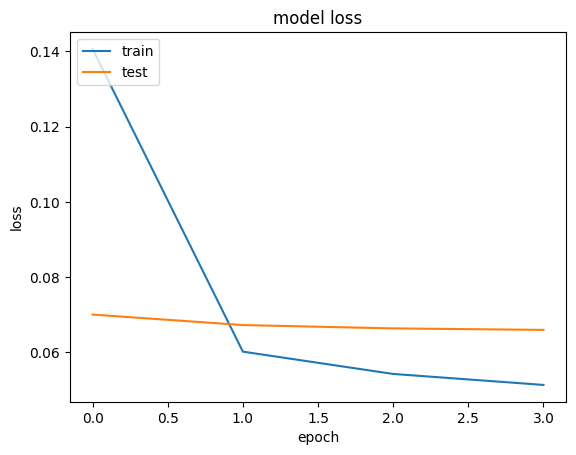

In [26]:
# summarize history for accuracy
plt.plot(acc)
plt.plot(val_acc)
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

# summarize history for loss
plt.plot(loss)
plt.plot(val_loss)
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [44]:
start_time = default_timer()
test['test'] = test['tg'].apply(lambda x: translate(model, x))
end_time = default_timer()
print('Mean time =', f'{(end_time - start_time)/len(test):.3f} s')

Mean time = 5.047 s


In [14]:
from Levenshtein import ratio, distance

test['ratio'] = test.apply(lambda x: ratio(x.fa, x.test), axis=1)
test['distance'] = test.apply(lambda x: distance(x.fa, x.test), axis=1)

In [15]:
def accuracy(refs, preds):
    refs = refs.strip().split()
    preds = preds.strip().split()
    right_words = sum(word in preds for word in refs)
    return right_words / max(len(preds), len(refs))

test['accuracy'] = test.apply(lambda x: accuracy(x.fa, x.test), axis=1)

Accuracy = 0.858
Relative accuracy = 0.934
Ratio = 0.990
Distance = 0.249


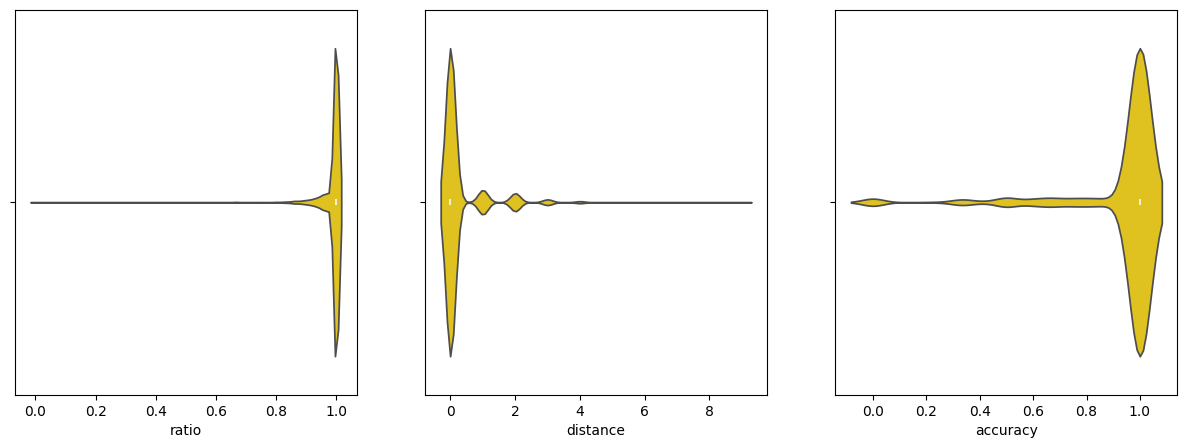

In [16]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

for idx, column_name in enumerate(test[['ratio', 'distance', 'accuracy']]):
    plt.subplot(1, 3, idx + 1)
    sns.violinplot(data=test, color="gold",
                 x=column_name)

print(f'Accuracy = {(len(test[test["ratio"]==1]) / len(test)):.3f}')
print(f'Relative accuracy = {(test["accuracy"].sum() / len(test)):.3f}')
print(f'Ratio = {(test["ratio"].sum() / len(test)):.3f}')
print(f'Distance = {(test["distance"].sum() / len(test)):.3f}')

In [23]:
example = ['тамоми одамон озод ба дунё меоянд ва',
           'аз лиҳози манзилату ҳуқуқ бо ҳам баробаранд',
           'ҳама соҳиби ақлу виҷдонанд',
           'бояд нисбат ба якдигар бародарвор муносабат намоянд']
result = ['تمام آدمان آزاد به دنیا می‌آیند و',
          'از لحاظ منزلت و حقوق با هم برابرند',
          'همه صاحب عقل و وجدانند',
          'باید نسبت به یکدیگر برادروار مناسبت نمایند']
for t, f in zip(example, result):
    t2 = translate(model, t)
    print('>', t2)
    print('+', f)
    print('Ratio:', ratio(t2, f))

W0000 00:00:1701913345.326921    2516 op_level_cost_estimator.cc:699] Error in PredictCost() for the op: op: "Softmax" attr { key: "T" value { type: DT_FLOAT } } inputs { dtype: DT_FLOAT shape { unknown_rank: true } } device { type: "CPU" vendor: "GenuineIntel" model: "106" frequency: 3292 num_cores: 4 environment { key: "cpu_instruction_set" value: "AVX SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 32768 l2_cache_size: 262144 l3_cache_size: 6291456 memory_size: 268435456 } outputs { dtype: DT_FLOAT shape { unknown_rank: true } }


> تمام آدمان آزاد به دنیا می‌آیند و
+ تمام آدمان آزاد به دنیا می‌آیند و
Ratio: 1.0
> از لحاظ منزلت و حقوق با هم برابرند
+ از لحاظ منزلت و حقوق با هم برابرند
Ratio: 1.0
> همه صاحب عقل و وجدانند
+ همه صاحب عقل و وجدانند
Ratio: 1.0
> باید نسبت به یکدیگر برادروار مناسبت نمایند
+ باید نسبت به یکدیگر برادروار مناسبت نمایند
Ratio: 1.0
